# Teorema del Límite Central (TLC)

**Métodos Estadísticos para Inteligencia Artificial — Especialización en Inteligencia Artificial**

Este notebook permite visualizar de manera sencilla el **Teorema del Límite Central**.

Partiremos de una población con distribución **exponencial**, claramente asimétrica y no normal. Luego extraeremos muchas muestras aleatorias de diferentes tamaños y estudiaremos la distribución de sus medias.

El objetivo es observar que, al aumentar el tamaño muestral *n*:

- la distribución de las medias muestrales se aproxima a una distribución normal;
- la media de las medias muestrales se aproxima a la media poblacional $\mu$;
- la desviación estándar de las medias se aproxima al error estándar $\sigma$/$\sqrt{n}$.

> **Importante:** el TLC no afirma que los datos originales se vuelvan normales. La aproximación normal corresponde a la **distribución de las medias muestrales**.


## 1. Importación de librerías

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
# Semilla para obtener resultados reproducibles
np.random.seed(182)

## 2. Generación de una población no normal

Utilizaremos una distribución exponencial con parámetro de escala 10. En esta parametrización:

$$\mu = 10, \sigma = 10$$

La distribución exponencial es deliberadamente elegida porque presenta una marcada asimetría positiva, lo que permite visualizar claramente el efecto del Teorema del Límite Central

In [3]:
# Parámetros
mu = 10
sigma = 10
N = 100000

# Generamos una población exponencial
poblacion = np.random.exponential(scale=mu, size=N)

print(f'Media teórica de la población: {mu:.2f}')
print(f'Media observada:               {np.mean(poblacion):.2f}')
print(f'Desvío estándar teórico:       {sigma:.2f}')
print(f'Desvío estándar observado:     {np.std(poblacion):.2f}')

Media teórica de la población: 10.00
Media observada:               10.06
Desvío estándar teórico:       10.00
Desvío estándar observado:     10.07


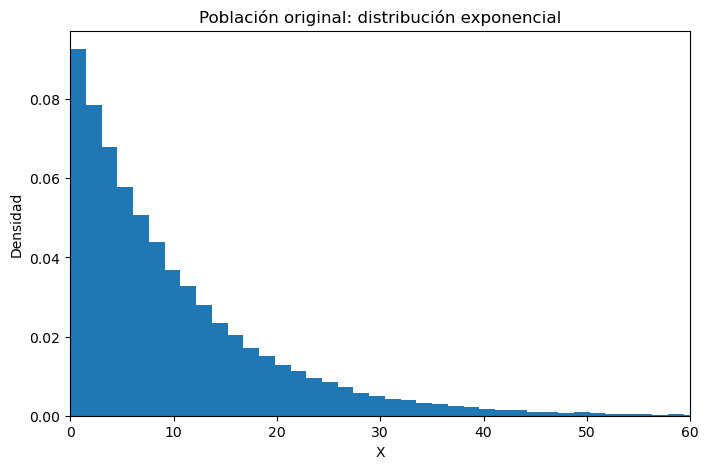

In [4]:
# Histograma de la población
plt.figure(figsize=(8, 5))
plt.hist(poblacion, bins=80, density=True)
plt.xlabel('X')
plt.ylabel('Densidad')
plt.title('Población original: distribución exponencial')
plt.xlim(0, 60)
plt.show()

La población original **no tiene forma de campana**: es fuertemente asimétrica hacia la derecha. Ahora estudiaremos qué ocurre con las medias obtenidas a partir de muestras aleatorias extraídas de esta población.


## 3. Extracción repetida de muestras

In [6]:
def generar_medias(poblacion, n, repeticiones=10000):
    '''Extrae muestras con reemplazo y devuelve sus medias'''
    medias = np.empty(repeticiones)

    for i in range(repeticiones):
        muestra = np.random.choice(poblacion, size=n, replace=True)
        medias[i] = np.mean(muestra)

    return medias

# Cantidad de repeticiones y tamaños muestrales
repeticiones = 10000
tamanios = [5, 30, 100]

medias = {}
for n in tamanios:
    medias[n] = generar_medias(poblacion, n, repeticiones)

## 4. Distribución de las medias para (n=5)

Comenzamos con muestras pequeñas. Según el TLC, la media muestral tiene media aproximadamente $\mu$ y error estándar $\frac{\sigma}{\sqrt{n}}$


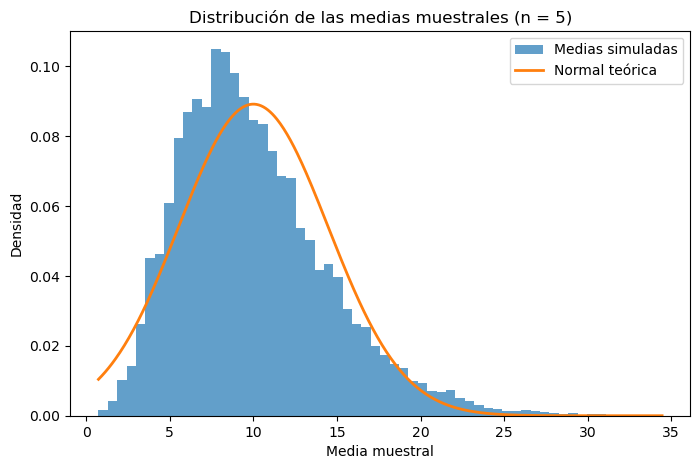

In [8]:
n = 5
datos = medias[n]
error_estandar = sigma / np.sqrt(n)

x = np.linspace(datos.min(), datos.max(), 500)

plt.figure(figsize=(8, 5))
plt.hist(datos, bins=60, density=True, alpha=0.7, label='Medias simuladas')
plt.plot(x, norm.pdf(x, loc=mu, scale=error_estandar), linewidth=2, label='Normal teórica')
plt.xlabel('Media muestral')
plt.ylabel('Densidad')
plt.title('Distribución de las medias muestrales (n = 5)')
plt.legend()
plt.show()

In [9]:
print(f'Media de las medias:           {np.mean(datos):.3f}')
print(f'Media poblacional teórica:     {mu:.3f}')
print(f'Desvío de las medias:          {np.std(datos):.3f}')
print(f'Error estándar teórico:        {error_estandar:.3f}')

Media de las medias:           10.049
Media poblacional teórica:     10.000
Desvío de las medias:          4.493
Error estándar teórico:        4.472


Con \(n=5\), la distribución de las medias ya es menos asimétrica que la población original, aunque todavía puede observarse cierta diferencia respecto de una distribución normal

## 5. Distribución de las medias para (n=30)

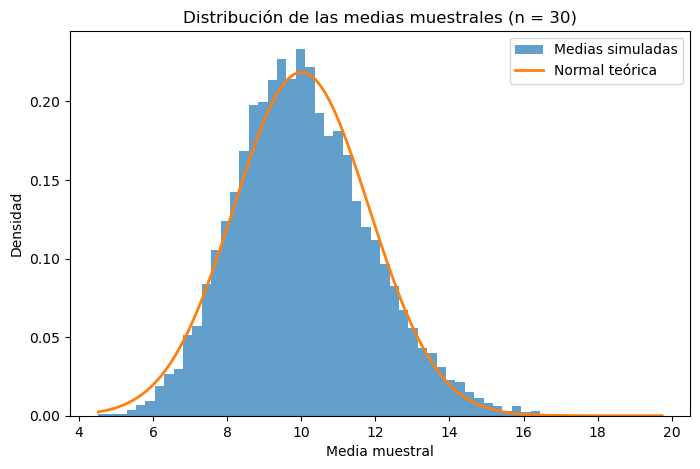

In [10]:
n = 30
datos = medias[n]
error_estandar = sigma / np.sqrt(n)

x = np.linspace(datos.min(), datos.max(), 500)

plt.figure(figsize=(8, 5))
plt.hist(datos, bins=60, density=True, alpha=0.7, label='Medias simuladas')
plt.plot(x, norm.pdf(x, loc=mu, scale=error_estandar),
         linewidth=2, label='Normal teórica')
plt.xlabel('Media muestral')
plt.ylabel('Densidad')
plt.title('Distribución de las medias muestrales (n = 30)')
plt.legend()
plt.show()

In [11]:
print(f'Media de las medias:           {np.mean(datos):.3f}')
print(f'Media poblacional teórica:     {mu:.3f}')
print(f'Desvío de las medias:          {np.std(datos):.3f}')
print(f'Error estándar teórico:        {error_estandar:.3f}')

Media de las medias:           10.059
Media poblacional teórica:     10.000
Desvío de las medias:          1.822
Error estándar teórico:        1.826


Para \(n=30\), la distribución de las medias presenta una forma mucho más cercana a una normal. El valor 30 suele utilizarse como referencia didáctica, pero **no constituye una regla universal**: el tamaño necesario para lograr una buena aproximación depende de la distribución de la población

## 6. Distribución de las medias para (n=100)

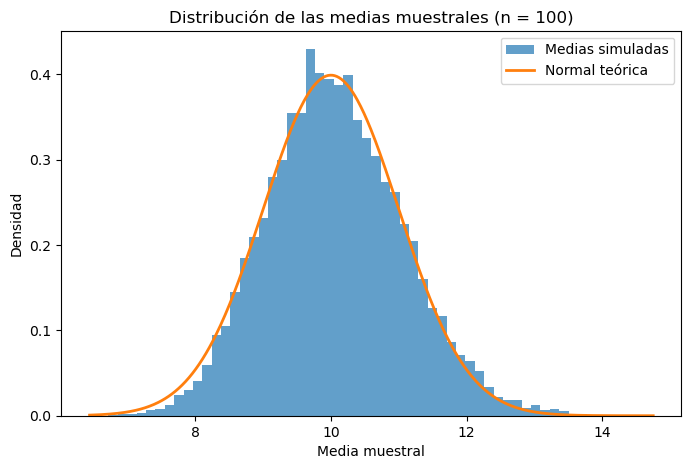

In [12]:
n = 100
datos = medias[n]
error_estandar = sigma / np.sqrt(n)

x = np.linspace(datos.min(), datos.max(), 500)

plt.figure(figsize=(8, 5))
plt.hist(datos, bins=60, density=True, alpha=0.7, label='Medias simuladas')
plt.plot(x, norm.pdf(x, loc=mu, scale=error_estandar), linewidth=2, label='Normal teórica')
plt.xlabel('Media muestral')
plt.ylabel('Densidad')
plt.title('Distribución de las medias muestrales (n = 100)')
plt.legend()
plt.show()

In [13]:
print(f'Media de las medias:           {np.mean(datos):.3f}')
print(f'Media poblacional teórica:     {mu:.3f}')
print(f'Desvío de las medias:          {np.std(datos):.3f}')
print(f'Error estándar teórico:        {error_estandar:.3f}')

Media de las medias:           10.067
Media poblacional teórica:     10.000
Desvío de las medias:          1.007
Error estándar teórico:        1.000


Con \(n=100\), la aproximación normal resulta mucho más evidente. Además, las medias se encuentran más concentradas alrededor de $\mu$, porque el error estándar disminuye al aumentar *n*.


## 7. Comparación de los tres tamaños muestrales


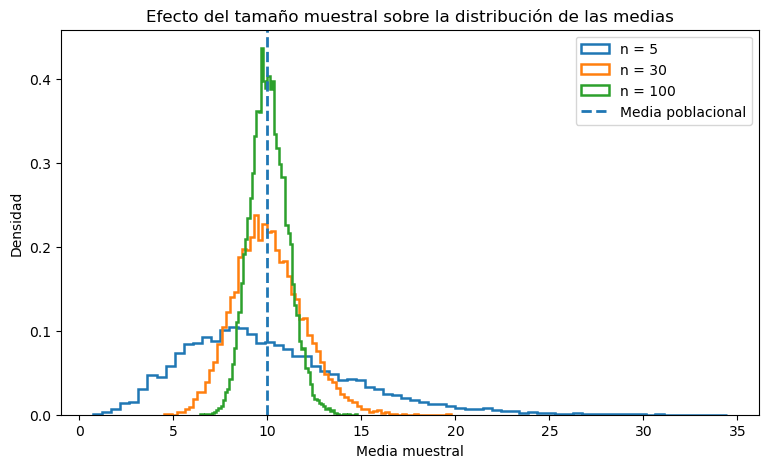

In [14]:
plt.figure(figsize=(9, 5))

for n in tamanios:
    plt.hist(medias[n], bins=70, density=True, histtype='step',
             linewidth=1.8, label=f'n = {n}')

plt.axvline(mu, linestyle='--', linewidth=2, label='Media poblacional')
plt.xlabel('Media muestral')
plt.ylabel('Densidad')
plt.title('Efecto del tamaño muestral sobre la distribución de las medias')
plt.legend()
plt.show()

El gráfico permite observar dos resultados fundamentales:

1. Las distribuciones de las medias se concentran alrededor de la misma media poblacional $\mu$.
2. Al aumentar *n*, disminuye su dispersión, porque el error estándar es $\frac{\sigma}{\sqrt{n}}$.


## 8. Comparación numérica

In [15]:
print('Comparación entre simulación y teoría')
print('-' * 72)
print(f"{'n':>5} {'Media medias':>15} {'Desvío medias':>17} {'σ/√n teórico':>17}")
print('-' * 72)

for n in tamanios:
    media_observada = np.mean(medias[n])
    desvio_observado = np.std(medias[n])
    ee_teorico = sigma / np.sqrt(n)

    print(f'{n:5d} {media_observada:15.3f} {desvio_observado:17.3f} {ee_teorico:17.3f}')

Comparación entre simulación y teoría
------------------------------------------------------------------------
    n    Media medias     Desvío medias      σ/√n teórico
------------------------------------------------------------------------
    5          10.049             4.493             4.472
   30          10.059             1.822             1.826
  100          10.067             1.007             1.000


## 9. Conclusiones

La simulación permite visualizar las principales ideas del **Teorema del Límite Central**:

- La población original utilizada en este ejemplo es exponencial y, por lo tanto, claramente no normal.
- Al tomar repetidamente muestras independientes y calcular sus medias, la distribución de esas medias se aproxima progresivamente a una distribución normal.
- La media de la distribución de las medias muestrales se aproxima a la media poblacional:

$$E(\bar{X}) = \mu$$

- Su desviación estándar, denominada **error estándar de la media**, disminuye al aumentar el tamaño de la muestra:

$$\sigma_{\bar X}=\frac{\sigma}{\sqrt{n}}$$

El TLC constituye una de las bases de la inferencia estadística y ayuda a comprender posteriormente los **intervalos de confianza** y los **contrastes de hipótesis**

### Para pensar

1. ¿Qué cambia entre los histogramas cuando aumenta *n*?
2. ¿La población original se vuelve normal?
3. ¿Por qué disminuye la dispersión de las medias muestrales?
4. ¿Qué ocurriría si la población original ya tuviera distribución normal?